Lab3- Persky Idan 215548512 , Golan Amir 216264333

# Lab 03 – Data Visualization: Seeing What the Numbers Hide
**Data Science Lab 83-554 · Bar-Ilan University · Dr. Alexandra Litinsky Simanovsky**

You already know how to plot. Today the question is different: **does the chart tell the truth?**

**The story.** You are the new data analyst of a ministry's climate unit. The Minister's office sends you a file of world energy and CO2 data compiled by a hurried colleague, and asks for a briefing. In seven blocks you will check whether the data can be trusted, draw who emits and how much, find out why countries differ, build charts for the public website, find the bugs behind four wrong numbers, write the one-page briefing for the Minister, and review what an AI assistant produced for the same task. About 40 graphs on the way.
You will work with real world energy and climate data (1990–2023). The data contain realistic problems, and a good chart is often the fastest way to find them.

| Session | Block | Topic | Exercises |
|---|---|---|---|
| 1 | 0 | Load, clean and look | 1–6 |
| | 1 | Matplotlib: who emits, and how much? | 7–14 |
| | 2 | Seaborn: why do countries differ? | 15–22 |
| | 3 | Plotly: interactive charts for the website | 23–27 |
| 2 | 4 | Find the bug | 28–31 |
| | 5 | Integrated challenge: the briefing | 32–36 |
| | 6 | Working with an LLM, critically | 37–40 |
| extra | 7 | More chart types ★ | 41–46 |

Plan: about 90 minutes in the first session and 45 in the second.

**★ = extra.** Exercises marked ★ (all of Block 7) are extra practice with more chart types: do them if you finish early. Whatever you do not finish in class, you finish on your own.

**How to work**
- Each exercise shows the **expected output** (a chart, a table, or a description of the result) under an empty cell. Write code that produces it, then run the cell.
- Hints are collapsed under each exercise. Try first, open them only if you are stuck.
- Where an exercise says *explain*, write your answer in a short comment. A number from your own output is part of a good answer.
- Exercises depend on each other and run **in order, once**: if a result looks strange, restart from the first cell instead of re-running a single cell (some cells change the data in place). Later exercises use `yearly`, `countries`, `aggregates`, `info`, `m`, `d19`, `ct` from earlier ones.

**Data** (folder `data/`)
- `countries_yearly.csv` – one row per nation and year: population, GDP, CO2 emissions, CO2 by fuel, energy use, and `renewables_share_pct` (renewables as a percent of electricity).
- `energy_mix.csv` – energy use by source in TWh (long format), 2000–2023.
- `country_info.csv` – continent and income tier per country code (`iso3`).

Source: Our World in Data (CO2 and energy datasets), licensed CC BY 4.0, adapted by the course staff for teaching.


## Block 0 – Load, clean and look: charts that expose data problems
The file arrives without documentation. Before any conclusion, look at it with charts: they find in seconds what a table hides.
**Toolbox for checking a table quickly:** `df.info()` and `df.dtypes` (types and missing values), `df[col].value_counts()` (every distinct value), `df.duplicated().sum()` (repeated rows), `df[col].unique()`, and above all: compare a total with a number you already trust.

Before any analysis, plot. In this block you will clean the data and, more importantly, notice **why** it needs cleaning by looking at charts.

In [268]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style="whitegrid")
yearly = pd.read_csv('Data/countries_yearly.csv')
energy = pd.read_csv('Data/energy_mix.csv')
info = pd.read_csv('Data/country_info.csv')
print(yearly.shape, energy.shape, info.shape)
yearly.head()

(5568, 12) (14837, 4) (144, 3)


,nation,year,iso3,population,gdp_usd,co2_mt,co2_per_person,coal_co2_mt,oil_co2_mt,gas_co2_mt,energy_twh,renewables_share_pct
0,Kyrgyzstan,2017,KGZ,6220148.0,2.887968e+10,9.364,1.505,3.391,4.710,0.579,46.675,91.477
1,Gambia,2015,GMB,2224530.0,3.514848e+09,0.583,0.262,NaN,0.583,NaN,2.313,0.000
2,USA,2018,USA,335056492.0,1.812469e+13,5361.236,16.001,1224.380,2305.441,1577.716,26768.988,17.450
3,Indonesia,2008,IDN,240157902.0,1.809491e+12,365.384,1.521,121.845,158.303,60.313,1564.584,16.895
4,Mexico,1991,MEX,84430565.0,8.651487e+11,329.831,3.907,15.510,246.535,55.268,1357.680,22.136


### Exercise 1 – First chart

**A line that stops.** Plot CO2 emissions (`co2_mt`, megatonnes) of `nation == 'United States'` against `year` as a line, using `fig, ax = plt.subplots()`. Sort by year first, add a title, axis labels, and rotate the x tick labels by 45°.
Use the data exactly as loaded (matplotlib draws text values as categories in the order they appear, so sort first). Then answer in a comment: **what is wrong with this chart?** Name one problem you can see in the chart, and one more that you can find with `yearly.dtypes`.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, '1990'),
  Text(1, 0, '1991'),
  Text(2, 0, '1992'),
  Text(3, 0, '1993'),
  Text(4, 0, '1994'),
  Text(5, 0, '1995'),
  Text(6, 0, '1996'),
  Text(7, 0, '1997'),
  Text(8, 0, '1998'),
  Text(9, 0, '1999'),
  Text(10, 0, '2000'),
  Text(11, 0, '2001'),
  Text(12, 0, '2002'),
  Text(13, 0, '2003'),
  Text(14, 0, '2004')])

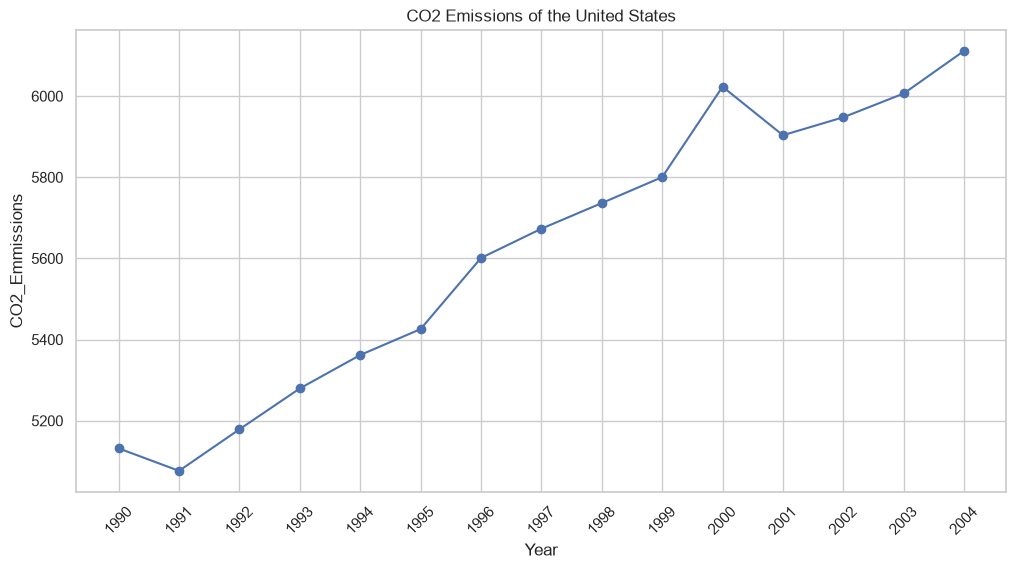

In [269]:
# Write your code here
fig, ax = plt.subplots(figsize=(12,6))
year_usa = yearly[yearly['nation']=='United States'].copy()
year_usa = year_usa.sort_values('year')
ax.plot(year_usa['year'],year_usa['co2_mt'],marker="o")
plt.title(label='CO2 Emissions of the United States')
plt.xlabel('Year')
plt.ylabel('CO2_Emmissions')
plt.xticks(rotation=45)

<details><summary><b>Hint 1</b></summary>

Look at the first and the last x tick. Does the data end where you expect?

</details>
<details><summary><b>Hint 2</b></summary>

`yearly['nation'].unique()` – search for other spellings of the same country.

</details>
<details><summary><b>Hint 3</b></summary>

`yearly.dtypes` – is `year` a number?

</details>

### Exercise 2 – Cleaning the year column

**Make `year` numeric, then drop duplicates.** The suffix `p` marks provisional 2023 values. In `yearly`, in this order:
(1) add a boolean column `provisional` (True where the year text ends with `p`) **before** touching `year`, (2) turn `year` into an integer, (3) remove exact duplicate rows (reset the index).
Print how many provisional rows remain **after** the duplicates are removed, how many duplicates you removed, and the new number of rows.

In [270]:
yearly['year'] = yearly['year'].astype(str)
yearly['provisional'] = yearly['year'].str.contains('p', na=False)
yearly['year'] = yearly['year'].str.replace('p', '', regex=False).astype(int)


In [271]:
# Write your code here
count_before = len(yearly)
yearly.drop_duplicates(inplace=True)
count_after = len(yearly)
print(f"Provisional Rows {len(yearly[yearly['provisional']==True])}| Duplicates removed {count_before - count_after}| Rows now: {len(yearly)} ")

Provisional Rows 102| Duplicates removed 60| Rows now: 5508 


C:\Users\Idan\AppData\Local\Temp\ipykernel_29392\2717483734.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  yearly.drop_duplicates(inplace=True)


<details><summary><b>Hint 1</b></summary>

`.str.endswith('p')` and `.str.rstrip('p')` work on a string column.

</details>
<details><summary><b>Hint 2</b></summary>

Create `provisional` **before** converting `year`, otherwise the marker is lost.

</details>
<details><summary><b>Hint 3</b></summary>

`duplicated()` then `drop_duplicates()`.

</details>

### Exercise 3 – One name per country

**One name per country.** The line in Exercise 1 stopped because of how names are stored. Make every country have exactly one name:
(1) for each `iso3` code, find its most frequent spelling (`name_by_iso`); (2) build a dictionary `rename_map` {other spelling: most frequent spelling} for every name that differs; (3) apply it to `yearly['nation']` **and** to `energy['nation']` (the energy table has no `iso3`). Print `rename_map`, and check that every name in `energy` now exists in `yearly`. Use the most frequent spelling exactly, even if it looks odd (for example `'Korea, South'`), because later exercises use these names (for example `'USA'`). This is a practical choice, not a rule: in real work you would ask the data owner for the official name.

In [272]:
# Write your code here
name_by_iso = yearly.groupby('iso3')['nation'].agg(lambda s: s.value_counts().index[0]).to_dict()
unique_combos = yearly.dropna(subset=['iso3'])[['iso3', 'nation']].drop_duplicates()
unique_combos['freq_name'] = unique_combos['iso3'].map(name_by_iso)
differing = unique_combos[unique_combos['nation'] != unique_combos['freq_name']]
rename_map = dict(zip(differing['nation'], differing['freq_name']))

# Strip potential trailing/leading whitespace from nation columns
yearly['nation'] = yearly['nation'].str.strip()
energy['nation'] = energy['nation'].str.strip()

# Apply renaming
yearly['nation'] = yearly['nation'].replace(rename_map)
energy['nation'] = energy['nation'].replace(rename_map)

print(rename_map)
print("Are all energy names in yearly?", energy['nation'].isin(yearly['nation']).all())

{'United States': 'USA', 'South Korea': 'Korea, South', 'Czechia': 'Czech Republic'}
Are all energy names in yearly? True


<details><summary><b>Hint 1</b></summary>

`groupby('iso3')['nation']` and `value_counts().index[0]` give the most frequent name.

</details>
<details><summary><b>Hint 2</b></summary>

Compare each row's name with `iso3.map(name_by_iso)` to find the rows that differ.

</details>
<details><summary><b>Hint 3</b></summary>

`Series.replace(dict)` applies a mapping and leaves other values untouched.

</details>

### Exercise 4 – Splitting the table

**Countries and aggregates.** Some rows are not countries. Find out how to recognise them, then split `yearly` into `countries` (with `iso3`) and `aggregates` (without), both with `.copy()`. Print the sorted list of aggregate names, and how many distinct countries there are.

In [273]:
yearly

,nation,year,iso3,population,gdp_usd,co2_mt,co2_per_person,coal_co2_mt,oil_co2_mt,gas_co2_mt,energy_twh,renewables_share_pct,provisional
0,Kyrgyzstan,2017,KGZ,6.220148e+06,2.887968e+10,9.364,1.505,3.391,4.710,0.579,46.675,91.477,False
1,Gambia,2015,GMB,2.224530e+06,3.514848e+09,0.583,0.262,NaN,0.583,NaN,2.313,0.000,False
2,USA,2018,USA,3.350565e+08,1.812469e+13,5361.236,16.001,1224.380,2305.441,1577.716,26768.988,17.450,False
3,Indonesia,2008,IDN,2.401579e+08,1.809491e+12,365.384,1.521,121.845,158.303,60.313,1564.584,16.895,False
4,Mexico,1991,MEX,8.443056e+07,8.651487e+11,329.831,3.907,15.510,246.535,55.268,1357.680,22.136,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5563,Libya,2004,LBY,5.736696e+06,7.941554e+10,56.854,9.911,0.000,34.605,12.865,223.347,0.000,False
5564,China,2022,CHN,1.425180e+09,2.696602e+13,11711.808,8.218,8468.947,1559.721,773.225,44516.492,30.181,False
5565,Libya,2009,LBY,6.366689e+06,1.655597e+11,51.627,8.109,NaN,31.340,11.235,249.987,0.000,False
5566,Oceania,2013,NaN,3.923394e+07,NaN,445.004,11.422,183.846,164.332,78.599,1795.159,23.098,False


In [274]:
# Recognise incorrect countries
yearly[yearly["iso3"].isna()] # Wherever there is NaN value in iso3 the nation is not a country eg: Europe is a continent

,nation,year,iso3,population,gdp_usd,co2_mt,co2_per_person,coal_co2_mt,oil_co2_mt,gas_co2_mt,energy_twh,renewables_share_pct,provisional
41,Oceania,2023,NaN,4.556314e+07,NaN,433.177,9.562,147.462,173.696,87.161,1897.110,41.648,False
44,Europe,2023,NaN,7.469662e+08,NaN,4887.137,6.546,1054.397,1895.550,1688.073,28746.484,40.036,True
47,Asia,2015,NaN,4.482088e+09,NaN,19070.406,4.255,10642.819,4426.652,2541.085,75114.688,18.339,False
49,European Union (27),1994,NaN,4.251890e+08,NaN,3589.454,8.442,1363.125,1492.620,583.860,17114.426,15.144,False
55,Lower-middle-income countries,2001,NaN,2.169846e+09,NaN,1848.146,0.852,671.004,726.752,282.479,6303.018,22.338,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5508,Asia,2007,NaN,4.090564e+09,NaN,14118.133,3.451,7664.360,3683.855,1717.877,57188.984,12.997,False
5525,Lower-middle-income countries,2010,NaN,2.550520e+09,NaN,2838.991,1.113,1146.915,977.428,486.323,9815.037,21.876,False
5540,High-income countries,2022,NaN,1.410112e+09,NaN,14274.797,10.153,3086.188,5768.652,4757.556,78006.219,27.706,False
5554,Low-income countries,2019,NaN,6.598753e+08,NaN,214.494,0.325,71.232,116.220,8.852,842.747,57.409,False


In [275]:
# Copy data
countries = yearly[yearly["iso3"].notna()].copy()
aggregates = yearly[yearly["iso3"].isna()].copy()

aggregates_sorted = sorted(aggregates["nation"].unique())
print(aggregates_sorted)
print(f"Countries: {countries["nation"].nunique()} | aggregate series: {len(aggregates_sorted)}")

['Africa', 'Asia', 'Europe', 'European Union (27)', 'High-income countries', 'Low-income countries', 'Lower-middle-income countries', 'North America', 'Oceania', 'South America', 'Upper-middle-income countries', 'World']
Countries: 150 | aggregate series: 12


<details><summary><b>Hint 1</b></summary>

Aggregates such as `World` or `Asia` have no ISO code.

</details>
<details><summary><b>Hint 2</b></summary>

`isna()` / `notna()` on the `iso3` column.

</details>

### Exercise 5 – How complete is the data?

**How complete is the data?** Using `countries`, count for every year how many countries have a value in `co2_mt`, `gdp_usd` and `renewables_share_pct`, and draw the three counts as three lines in one chart (legend, axis labels, title). Print the three counts for 1990 and for 2019.
In a comment: which of the three variables would you trust least for a trend that starts in 1990, and why?

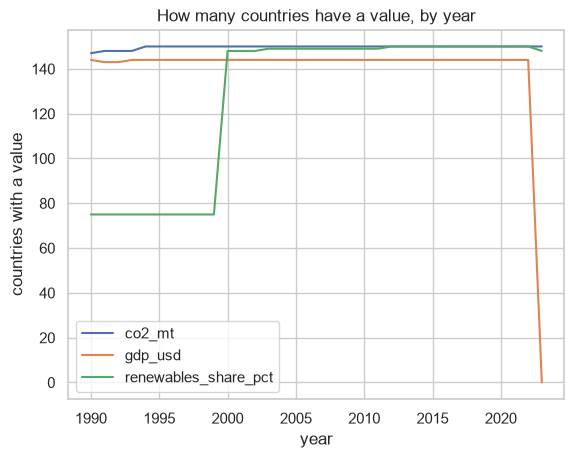

In [276]:
grouped_by_year = countries.groupby("year")[["co2_mt", "gdp_usd", "renewables_share_pct"]].count()

plt.plot(grouped_by_year.index, grouped_by_year)
plt.legend(grouped_by_year.columns)
plt.xlabel("year")
plt.ylabel("countries with a value")
plt.title("How many countries have a value, by year")
plt.show()


# I would trust renewables_share_pct the least since it starts very low and compared to other columns.

<details><summary><b>Hint 1</b></summary>

`df.groupby('year')[[cols]].count()` counts the non-missing values per column and year.

</details>
<details><summary><b>Hint 2</b></summary>

`cov.plot(ax=ax)` draws one line per column.

</details>
<details><summary><b>Hint 3</b></summary>

Self-check: your chart has three lines; one of them starts clearly lower than the other two.

</details>

### Exercise 6 – The ten largest CO2 emitters, 2019

**A chart that finds a unit error.** (a) Draw a horizontal bar chart (`ax.barh`) of the 10 countries with the highest `co2_mt` in 2019 (from `countries`). One bar is absurd.
(b) Prove it with two printed checks: that country's `co2_mt` compared with the `World` row of `aggregates`, and the per-person value implied by `co2_mt * 1e6 / population` compared with the reported `co2_per_person`.
(c) That country reports in a different unit from all the others (in the four columns `co2_mt`, `coal_co2_mt`, `oil_co2_mt`, `gas_co2_mt`). Correct them **in `countries`** and draw the chart again. Run this cell once: running it twice corrects the values twice.

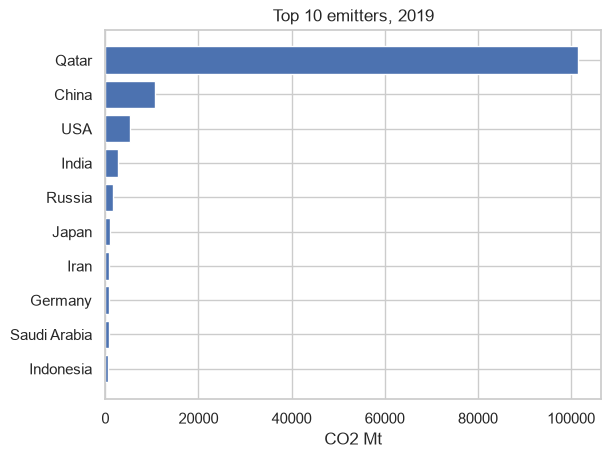

In [277]:
# (a)
# Filter top 10 co2 emitters of 2019
top_ten2019_co2 = (countries[countries["year"] == 2019]).sort_values(by="co2_mt", ascending = False).iloc[:10, :]

# Print barplot
plt.barh(top_ten2019_co2["nation"], top_ten2019_co2["co2_mt"])
plt.title("Top 10 emitters, 2019")
plt.xlabel("CO2 Mt")
plt.gca().invert_yaxis()

Calculated per-person value: 36251.83930817351 | Written per-person value: 36.252


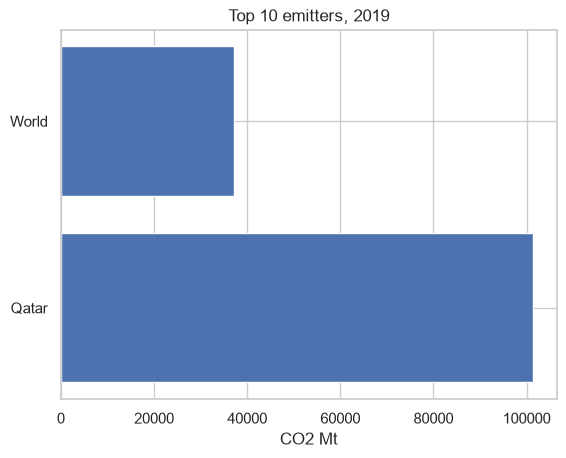

In [278]:
# (b)
# Filter only "World" row in 2019
aggregates_world = aggregates[(aggregates["nation"] == "World") & (aggregates["year"] == 2019) ]

# Print barplot
plt.barh(["World", "Qatar"], [aggregates_world["co2_mt"].iloc[0], top_ten2019_co2["co2_mt"].iloc[0]])
plt.title("Top 10 emitters, 2019")
plt.xlabel("CO2 Mt")
plt.gca().invert_yaxis()

# PP value
print(f"Calculated per-person value: {top_ten2019_co2.iloc[0]["co2_mt"] * 1e6 / top_ten2019_co2.iloc[0]["population"]} | Written per-person value: {top_ten2019_co2.iloc[0]["co2_per_person"]}")

# The calculated pp value is 1000 times bigger than the written pp value

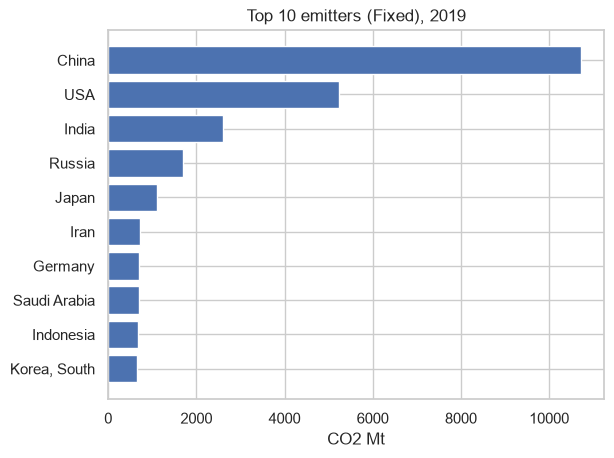

In [279]:
# (c)
# Divide by 1000
countries.loc[countries["nation"] == "Qatar", ["co2_mt", "coal_co2_mt", "oil_co2_mt", "gas_co2_mt"]] /= 1000


# Filter top 10 co2 emitters of 2019
top_ten2019_co2 = (countries[countries["year"] == 2019]).sort_values(by="co2_mt", ascending = False).iloc[:10, :]


# Print barplot
plt.barh(top_ten2019_co2["nation"], top_ten2019_co2["co2_mt"])
plt.title("Top 10 emitters (Fixed), 2019")
plt.xlabel("CO2 Mt")
plt.gca().invert_yaxis()

<details><summary><b>Hint 1</b></summary>

`nlargest(10, 'co2_mt')` then `sort_values` so the biggest bar ends up on top in `barh`.

</details>
<details><summary><b>Hint 2</b></summary>

A single country cannot emit more than the whole world. The implied per-person value should match the reported one – by what factor does it not?

</details>
<details><summary><b>Hint 3</b></summary>

Assignment on a subset of rows and columns: `df.loc[mask, columns] = ...`.

</details>

## Block 1 – Matplotlib: who emits, and how much?
The Minister's first question: show me the emitters. Everything in matplotlib hangs on two objects: the **Figure** (the canvas) and the **Axes** (one plot on it). Work with `fig, ax = plt.subplots(...)` and call methods on `ax`; it scales from one chart to a dashboard.

In [280]:
focus = ['USA', 'China', 'India', 'Germany', 'Israel']
palette = {'Africa': '#e15759', 'Americas': '#4e79a7', 'Asia': '#f28e2b', 'Europe': '#59a14f', 'Oceania': '#b07aa1', 'Unknown': '#999999'}
tier_order = ['Low', 'Lower-middle', 'Upper-middle', 'High']
focus

['USA', 'China', 'India', 'Germany', 'Israel']

### Exercise 7 – Five countries over time

**Five countries over time.** Pivot `countries` into a table `wide` (one column per country in `focus`, rows = year) and draw CO2 emissions (`co2_mt`) with one line per country, a legend, title and axis labels. Add a dashed vertical line at 2020 with the annotation `COVID-19`.
Then print, for each country, the **percentage change between 2007 and 2020** (rounded to 1 decimal).

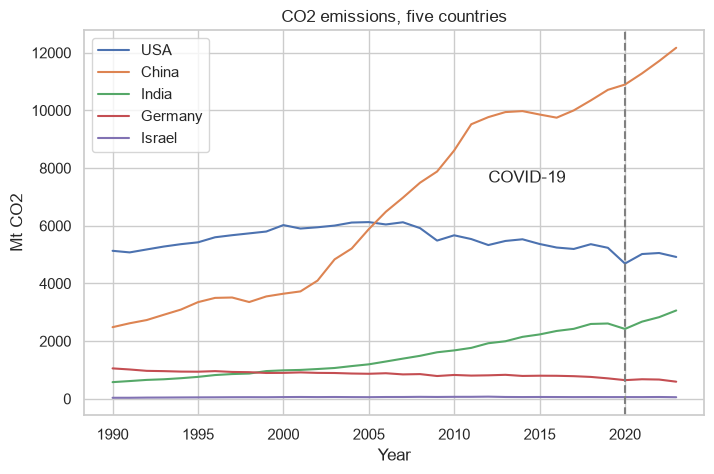

nation
USA       -23.4
China      56.2
India      73.9
Germany   -23.5
Israel     -5.6
dtype: float64


In [281]:
# Creating pivot table
wide = countries.pivot(index="year", columns="nation", values="co2_mt")[focus]


fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(wide.index, wide)
ax.set_title("CO2 emissions, five countries")
ax.legend(wide.columns)
ax.set_xlabel("Year")
ax.set_ylabel("Mt CO2")
ax.axvline(2020, linestyle="--", color="gray")
ax.annotate(
    "COVID-19",
    xy=(2020, 6000),
    xytext=(2012, 7500),
)
plt.show()

# Percentage change between 2007 and 2020
pct_change = ((wide.loc[2020] / wide.loc[2007] - 1) * 100).round(1)
print(pct_change)

<details><summary><b>Hint 1</b></summary>

`pivot(index='year', columns='nation', values='co2_mt')` gives one column per country.

</details>
<details><summary><b>Hint 2</b></summary>

`ax.axvline(x)` draws the vertical line; `ax.annotate(text, xy=..., xytext=..., arrowprops=...)` adds the label.

</details>
<details><summary><b>Hint 3</b></summary>

Percentage change: `(value_2020 / value_2007 - 1) * 100`.

</details>

### Exercise 8 – Which scale?

**Which scale?** In one figure with two side-by-side Axes, draw the same five lines on a **linear** y axis (left) and a **logarithmic** y axis (right, `ax.set_yscale('log')`). Reuse `wide` from the previous exercise.
Print the factor by which each country's CO2 grew between 1990 and 2019 (rounded to 1 decimal). In a comment: on which of the two scales can you see how fast Israel's emissions grew, and what does a straight line mean on a log axis?

**Expected result (described, no picture or output is shown):** One Figure with two side-by-side Axes showing the same five lines, one with a linear y axis and one with a logarithmic y axis, titled accordingly; the table of 1990-to-2019 growth factors printed with one decimal; two comment lines answering the two questions.

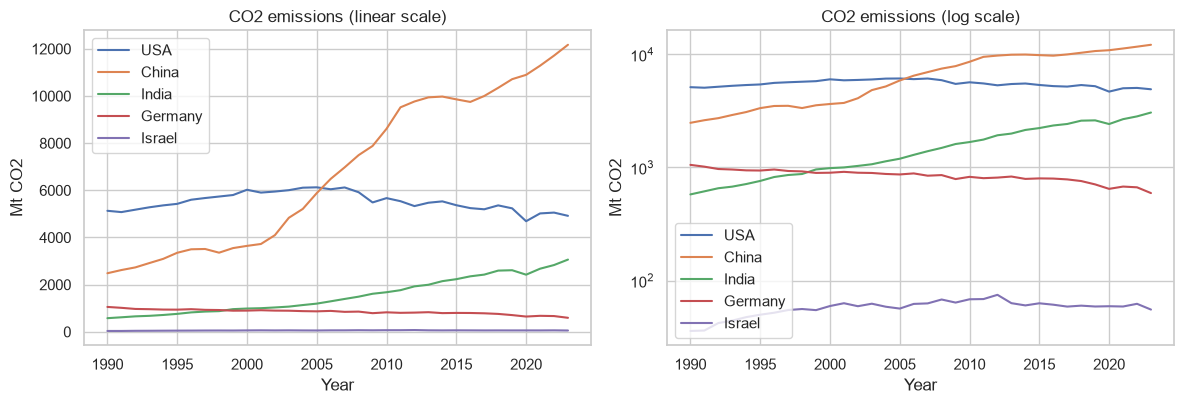

nation
USA        1.0
China      4.3
India      4.5
Germany    0.7
Israel     1.6
dtype: float64


In [282]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

for ax, scale in ((ax1, "linear"), (ax2, "log")):
    ax.plot(wide.index, wide)
    ax.set_yscale(scale)
    ax.set_title(f"CO2 emissions ({scale} scale)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Mt CO2")
    ax.legend(wide.columns)

plt.tight_layout()
plt.show()

# Growth factor between 1990 and 2019
growth_factor = (wide.loc[2019] / wide.loc[1990]).round(1)
print(growth_factor)

# We can see how fast Israel's emissions grew on the logarithmic scale (on the linear scale, Israel is flattened near zero because China and the USA are much larger).
# A straight line on a logarithmic axis means constant percentage (exponential) growth per year.

<details><summary><b>Hint 1</b></summary>

`plt.subplots(1, 2, ...)` returns two Axes.

</details>
<details><summary><b>Hint 2</b></summary>

`ax.set_yscale('log')`.

</details>
<details><summary><b>Hint 3</b></summary>

A straight line on a log axis means constant percentage growth.

</details>
<details><summary><b>Hint 4</b></summary>

Skeleton: `fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))`, then `for ax, scale in ((ax1, 'linear'), (ax2, 'log')):` loop over `focus`, `ax.plot(wide.index, wide[n], label=n)` and `ax.set_yscale(scale)`.

</details>
<details><summary><b>Hint 5</b></summary>

Self-check: your printed table has 5 numbers; one of them is below 1 (a country that shrank) and two are above 4.

</details>

### Exercise 9 – Grouped bars and shares

**Grouped bars and shares.** For 2019 and the countries `['USA', 'China', 'India', 'Germany', 'Israel', 'Japan']`, draw CO2 from coal, oil and gas (`coal_co2_mt`, `oil_co2_mt`, `gas_co2_mt`) in **two panels** of one Figure: (1) **grouped** bars in Mt, (2) **stacked** bars as **percent of each country's coal + oil + gas total** (every bar reaches 100). Use `ax.bar` with `np.arange` offsets for the grouped version and `bottom=` for the stacked one.
Print each country's coal share rounded to a whole number. In a comment: Israel is almost invisible in panel 1. Why, and which panel answers 'what is each country's fuel mix?'

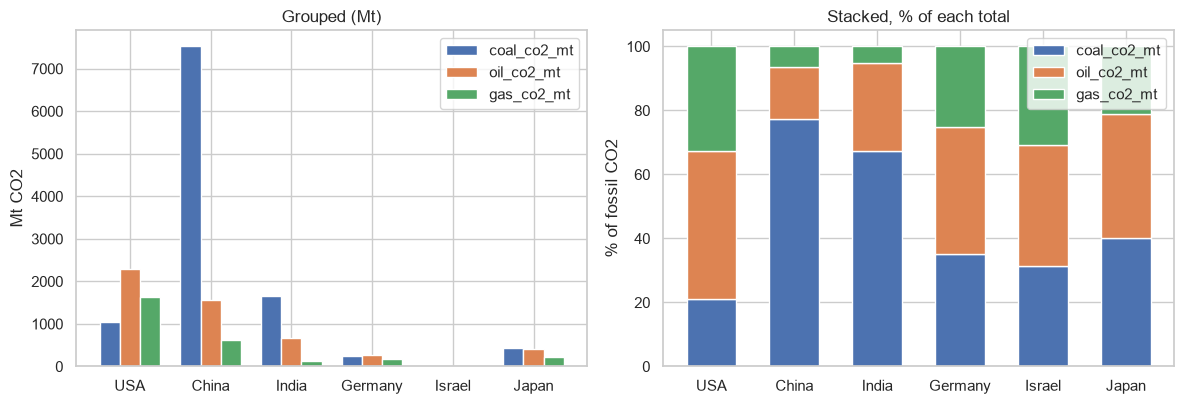

nation
USA        21.0
China      77.0
India      67.0
Germany    35.0
Israel     32.0
Japan      40.0
Name: coal_co2_mt, dtype: float64


In [283]:
# Filtering needed countries in 2019 
target_nations = ['USA', 'China', 'India', 'Germany', 'Israel', 'Japan']
fuels = ['coal_co2_mt', 'oil_co2_mt', 'gas_co2_mt']
UCIGIJ_countries_2019 = (countries[countries["year"] == 2019].set_index("nation").loc[target_nations, fuels])

# Plotting graphs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

x = np.arange(len(target_nations))
width = 0.25

# Panel 1: Grouped bars
for i, fuel in enumerate(fuels):
    ax1.bar(x + (i - 1) * width, UCIGIJ_countries_2019[fuel], width=width, label=fuel)

ax1.set_xticks(x)
ax1.set_xticklabels(target_nations)
ax1.set_title("Grouped (Mt)")
ax1.set_ylabel("Mt CO2")
ax1.legend()


# Panel 2: Stacked bars
countries_shares = UCIGIJ_countries_2019.div(UCIGIJ_countries_2019.sum(axis = 1), axis = 0) * 100
bottom = np.zeros(len(target_nations))

for i, fuel in enumerate(fuels):
    ax2.bar(x, countries_shares[fuel], width=0.6, bottom=bottom, label=fuel)
    bottom += countries_shares[fuel].values

ax2.set_xticks(x)
ax2.set_xticklabels(target_nations)
ax2.set_title("Stacked, % of each total")
ax2.set_ylabel("% of fossil CO2")
ax2.legend()


plt.tight_layout()
plt.show()


# Print each country's coal share rounded to a whole number
print(countries_shares["coal_co2_mt"].round(0))

<details><summary><b>Hint 1</b></summary>

For grouped bars shift each series by `(i - 1) * width`; the three bars are centred on the tick.

</details>
<details><summary><b>Hint 2</b></summary>

For the stacked panel divide each row by its own total first (`df.div(df.sum(axis=1), axis=0) * 100`), then keep a running `bottom` array.

</details>
<details><summary><b>Hint 3</b></summary>

Round with `.round(0)`.

</details>

### Exercise 10 – A bubble chart with four variables

**A bubble chart with four variables.** Build `m`: the 2019 rows of `countries` with non-missing `gdp_usd`, `population` and `co2_per_person`, joined to `info[['iso3', 'continent', 'gdp_tier']]` with a **left** join; fill missing `continent` with `'Unknown'`; add `gdp_pc = gdp_usd / population`.
Draw a scatter (`ax.scatter`, one call per continent): x = `gdp_pc` on a log axis, y = `co2_per_person`, bubble size proportional to `population`, colour from `palette`. Annotate the three most populous countries and add a legend titled `Continent`. Rows with missing GDP, population or CO2 cannot be drawn, so fewer than 150 countries remain: print how many are drawn and how many of them have no continent. (`info` does not list every country, which is why a continent can be missing; a left join keeps those countries.)

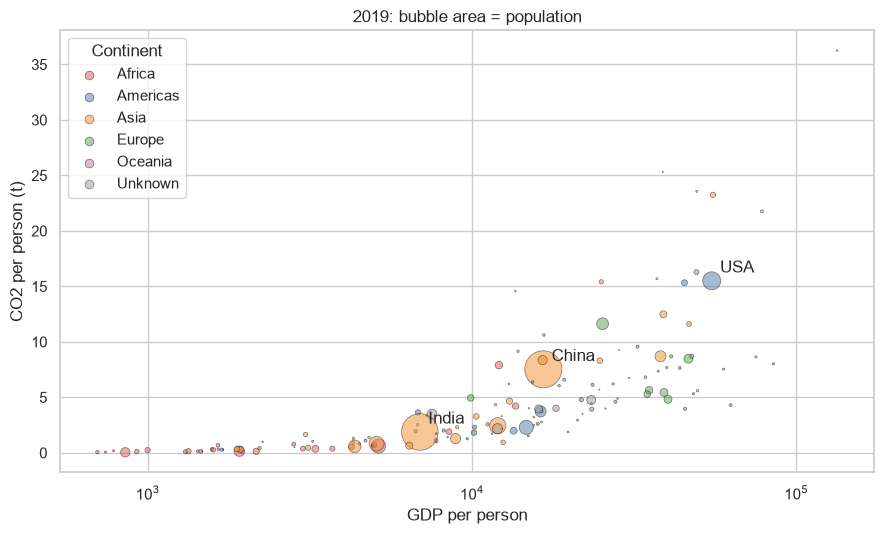

Countries drawn: 144 | Unknown continent: 6


In [284]:
# Creating m and merging with info
m = (
    countries[countries["year"] == 2019]
    .dropna(subset=["gdp_usd", "population", "co2_per_person"])
    .merge(info[["iso3", "continent", "gdp_tier"]], on="iso3", how="left")
)

# Filling continent nan values with 'Unknown'
m["continent"] = m["continent"].fillna('Unknown')

# Creating new column
m["gdp_pc"] = m["gdp_usd"] / m["population"]


# Plotting scatter plot
fig, ax = plt.subplots(figsize = (9, 5.5))

for cont, color in palette.items():
    sub = m[m["continent"] == cont]
    ax.scatter(
        sub["gdp_pc"],
        sub["co2_per_person"],
        s=sub["population"] / 2e6,  # proportional to population
        color=color,
        alpha=0.5,
        edgecolors="black",
        linewidth=0.5,
        label=cont,
    )

ax.set_xscale("log")
ax.set_title("2019: bubble area = population")
ax.set_xlabel("GDP per person")
ax.set_ylabel("CO2 per person (t)")

# Annotate the 3 most populous countries
for _, row in m.nlargest(3, "population").iterrows():
    ax.annotate(
        row["nation"],
        xy=(row["gdp_pc"], row["co2_per_person"]),
        xytext=(6, 6),
        textcoords="offset points",
    )

# Legend titled 'Continent' (with uniform marker sizes per Hint 3)
leg = ax.legend(title="Continent")
for h in leg.legend_handles:
    h.set_sizes([40])

plt.tight_layout()
plt.show()

# Print how many countries are drawn and how many have no continent
print(f"Countries drawn: {len(m)} | Unknown continent: {(m['continent'] == 'Unknown').sum()}")


<details><summary><b>Hint 1</b></summary>

`dropna(subset=[...])`, then `merge(..., how='left')`.

</details>
<details><summary><b>Hint 2</b></summary>

`s=` in `ax.scatter` is the area of the marker: divide the population by a constant to get sensible sizes.

</details>
<details><summary><b>Hint 3</b></summary>

Legend marker sizes copy the bubble sizes: `leg.legend_handles` lets you reset them with `h.set_sizes([40])`.

</details>

### Exercise 11 – A lollipop ranking

**A lollipop ranking.** From `m`, take the countries with a population above 5 million and draw the 15 with the highest `co2_per_person` as a lollipop chart: a thin horizontal line from 0 (`ax.hlines`) with a dot at the end (`ax.scatter`), sorted so the highest is on top, with the value written next to each dot. Print the top 3 with one decimal. In a comment: why filter by population?

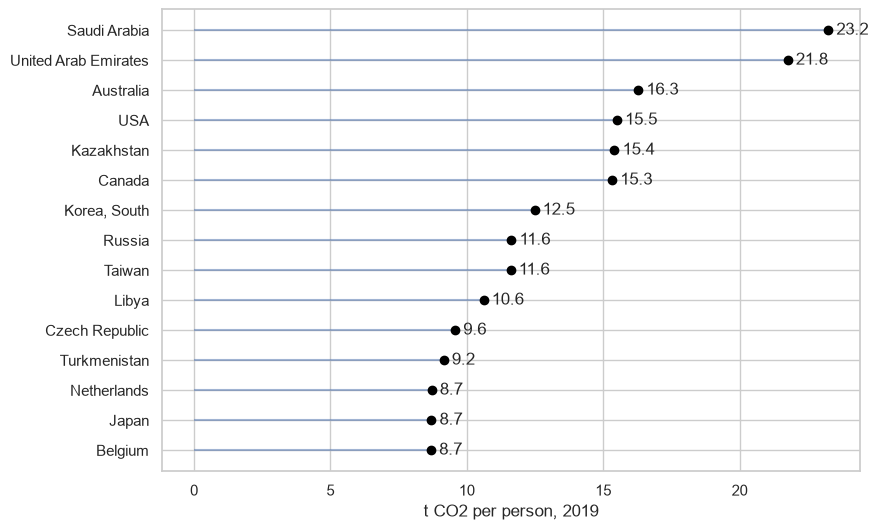

nation
Saudi Arabia            23.2
United Arab Emirates    21.8
Australia               16.3
Name: co2_per_person, dtype: float64


In [327]:
m_above_5m_largest = m[m["population"] > 5000000].nlargest(15, "co2_per_person").sort_values(by = "co2_per_person", ascending = False)

fig, ax = plt.subplots(figsize = (9, 6))

# Create dots
ax.scatter(m_above_5m_largest["co2_per_person"], m_above_5m_largest["nation"], color="black", zorder=3,)

# Create lines to each dot
ax.hlines(m_above_5m_largest["nation"], 0, m_above_5m_largest["co2_per_person"], alpha=0.5)

# Write the value next to each dot
for val, nation in zip(m_above_5m_largest["co2_per_person"], m_above_5m_largest["nation"]):
    ax.text(val + 0.3, nation, f"{val:.1f}", va="center")

ax.set_xlabel("t CO2 per person, 2019")
plt.gca().invert_yaxis()
plt.show()


# Print the top 3 with one decimal
print(m_above_5m_largest.set_index("nation")["co2_per_person"].head(3).round(1))

# We filter by nation because very small states or island nations (e.g., Qatar, Kuwait, Trinidad & Tobago) can have extreme per-capita emissions -  
# due to large oil/gas/industrial output divided by a tiny population, -
# dominating the ranking even though their total global impact is small. 

<details><summary><b>Hint 1</b></summary>

`ax.hlines(y_labels, 0, values)` and `ax.scatter(values, y_labels)` share the same y labels.

</details>
<details><summary><b>Hint 2</b></summary>

Sort ascending before plotting: the first row is drawn at the bottom.

</details>

### Exercise 12 – Two axes, one story

**Two axes, one story.** For Israel (`countries`, sorted by year) draw total `co2_mt` on the left axis and `co2_per_person` on the right axis (`ax.twinx()`) with axis labels coloured like their lines. Print the percentage change between 1990 and 2022 of the total, of the per-person value and of the population.
In a comment: how can both the total go up and the per-person value go down, and what is the danger of a chart with two y axes?

In [355]:
israel_masked

,nation,iso3,population,gdp_usd,co2_mt,co2_per_person,coal_co2_mt,oil_co2_mt,gas_co2_mt,energy_twh,renewables_share_pct,provisional
year,,,,,,,,,,,,
1990,Israel,ISR,4544995.0,9.326827e+10,35.824,7.882,9.950,24.821,0.066,129.135,0.014,False
1991,Israel,ISR,4779892.0,9.723534e+10,36.148,7.563,10.861,24.046,0.048,131.278,0.028,False
1992,Israel,ISR,4957240.0,1.038600e+11,42.082,8.489,13.370,27.363,0.048,153.197,0.117,False
1993,Israel,ISR,5086041.0,1.074240e+11,44.235,8.697,15.112,27.618,0.048,166.366,0.100,False
1994,Israel,ISR,5216697.0,1.145721e+11,47.475,9.101,16.017,29.908,0.044,173.569,0.081,False
1995,Israel,ISR,5354734.0,1.252197e+11,49.866,9.312,17.551,30.371,0.044,195.208,0.082,False
1996,Israel,ISR,5499555.0,1.317483e+11,51.936,9.444,20.907,29.327,0.029,202.297,0.074,False
1997,Israel,ISR,5646476.0,1.365295e+11,54.866,9.717,23.047,30.070,0.029,221.213,0.071,False
1998,Israel,ISR,5790143.0,1.415243e+11,56.010,9.673,24.791,29.008,0.022,232.794,0.066,False


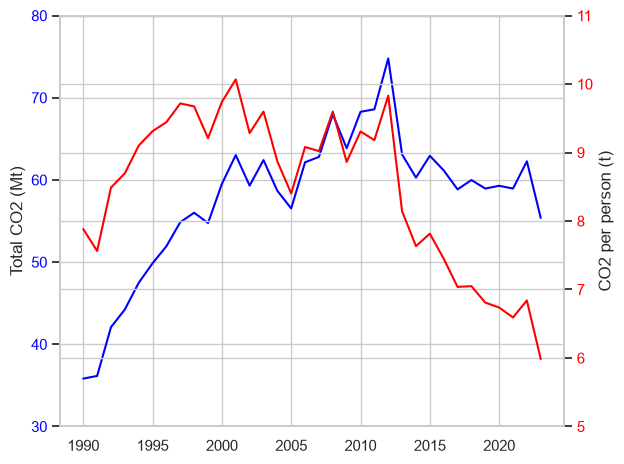

co2_mt             74.0
co2_per_person    -13.0
population        100.0
dtype: float64


In [360]:
# Write your code here
israel_masked = countries[countries["nation"] == "Israel"].sort_values(by="year")

fig, ax1 = plt.subplots()

# Co2 mt plot
ax1.plot(israel_masked["year"], israel_masked["co2_mt"], color = "blue")
ax1.set_ylabel("Total CO2 (Mt)")
ax1.tick_params(axis='y', labelcolor = "blue")
ax1.set_ylim(30, 80)

# Co2 pp plot
ax2 = ax1.twinx()
ax2.plot(israel_masked["year"], israel_masked["co2_per_person"], color = "red")
ax2.set_ylabel("CO2 per person (t)")
ax2.tick_params(axis='y', labelcolor="red")
ax2.set_ylim(5.0, 11.0)

fig.tight_layout() 
plt.show()


# Percentage change between 1990 and 2022
isr_idx = israel_masked.set_index("year")
cols = ["co2_mt", "co2_per_person", "population"]
print(((isr_idx.loc[2022, cols] / isr_idx.loc[1990, cols] - 1) * 100).round(0))

# Israel's population grew faster than its total CO2 emissions thus effecting the total going up but the pp going down.
# The danger of two y axes is that each axis has its own scale, which can make lines cross or show false visual comparisons.

<details><summary><b>Hint 1</b></summary>

`ax2 = ax1.twinx()` shares the x axis.

</details>
<details><summary><b>Hint 2</b></summary>

Percentage change: `value_2022 / value_1990 - 1`.

</details>

### Exercise 13 – Stacked areas over time

**Stacked areas over time.** For the USA draw CO2 from coal, oil and gas (`coal_co2_mt`, `oil_co2_mt`, `gas_co2_mt`) as a stacked area chart over the years (`ax.stackplot`) with a legend. Print each fuel's share (%, 1 decimal) in 1990 and in 2022.

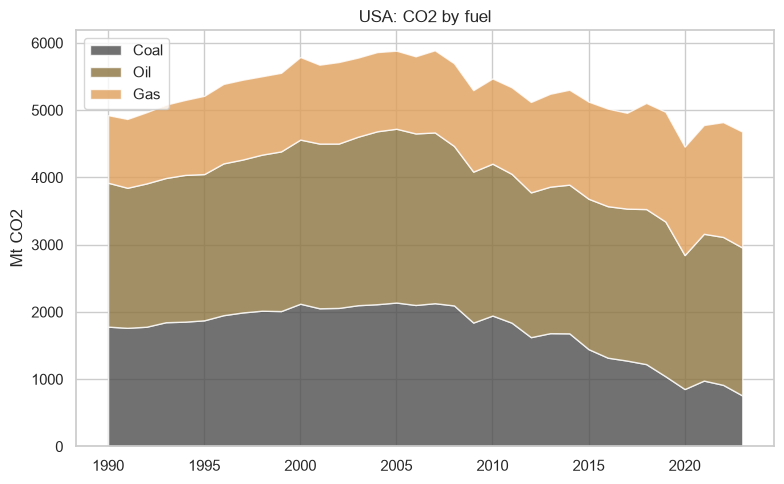

,coal_co2_mt,oil_co2_mt,gas_co2_mt
year,,,
1990,36.2,43.4,20.4
2022,19.0,45.6,35.4


In [384]:
# Stacked areas
usa_masked = countries[countries["nation"] == "USA"].sort_values(by="year")
cols = ["Coal", "Oil", "Gas"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.stackplot(usa_masked["year"], usa_masked["coal_co2_mt"], usa_masked["oil_co2_mt"], usa_masked["gas_co2_mt"], labels=cols, alpha=0.8, colors=["#4D4D4D", "#8C733F", "#E09F5B"])

ax.set_title("USA: CO2 by fuel")
ax.set_ylabel("Mt CO2")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# Fuel share table
fuel_share = usa_masked[usa_masked["year"].isin([1990, 2022])].set_index("year")[["coal_co2_mt", "oil_co2_mt", "gas_co2_mt"]]
fuel_share = (fuel_share.div(fuel_share.sum(axis=1), axis=0) * 100).round(1)
fuel_share

<details><summary><b>Hint 1</b></summary>

`ax.stackplot(x, y1, y2, y3, labels=[...])`.

</details>
<details><summary><b>Hint 2</b></summary>

Shares: divide each row by its own sum.

</details>

### Exercise 14 – A small dashboard

**A small dashboard.** For Germany (from `countries`, sorted by year) build a 2×2 grid of line charts that share the x axis (`sharex=True`): `co2_mt`, `co2_per_person`, `energy_twh`, `renewables_share_pct`. Give each panel its own title, add `fig.suptitle`, and finish with `fig.tight_layout()`. Mark provisional values (column `provisional`) with a hollow red circle.
Print Germany's change in `co2_mt` between 1990 and 2022 as a percentage.

In [288]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`plt.subplots(2, 2, sharex=True)` returns a 2×2 array of Axes; `axes.ravel()` flattens it.

</details>
<details><summary><b>Hint 2</b></summary>

Loop over a list of `(column, title)` pairs.

</details>

## Block 2 – Seaborn: why do countries differ?
Now the analysis: groups, distributions, relationships. Seaborn works on whole tables, and you must know what it computes for you.
**Seaborn in four lines:** functions take `data=` and column names (`x=`, `y=`, `hue=`); `hue` splits by colour; many functions **aggregate for you** (for example `lineplot` draws a mean with a confidence band) unless you pass `estimator=None`; `relplot`/`catplot` can make one panel per group (`col=`).

Seaborn works on whole DataFrames: you say *which columns*, it handles grouping, colours and statistics. The price: you must know what it computes for you.

### Exercise 15 – Box plus points

**Box plus points.** Build `d19`: the 2019 rows of `countries` joined (left) to `info[['iso3', 'continent', 'gdp_tier']]`, with missing `continent` set to `'Unknown'` and a column `gdp_pc = gdp_usd / population`.
Draw `co2_per_person` by continent: a box plot (`showfliers=False`, ordered by the median) with a strip plot on top showing every country. Print the median and the inter-quartile range (IQR) per continent.

**Expected result (described, no picture or output is shown):** A box plot per continent ordered by median, with every country drawn on top as a dot, plus a table with the median and the IQR per continent, sorted by median.

In [289]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`order=` takes the category order; `groupby(...).median().sort_values().index` produces it.

</details>
<details><summary><b>Hint 2</b></summary>

Boxes hide the individual points: draw them again with `stripplot` on the same Axes.

</details>
<details><summary><b>Hint 3</b></summary>

`s.quantile(.75) - s.quantile(.25)` is the IQR.

</details>
<details><summary><b>Hint 4</b></summary>

Skeleton: `fig, ax = plt.subplots()`; `sns.boxplot(data=d19, x=..., y=..., order=order, showfliers=False, ax=ax)`; `sns.stripplot(data=d19, x=..., y=..., order=order, ax=ax)`; the table with `groupby('continent')[col].agg(median='median', iqr=...)`.

</details>
<details><summary><b>Hint 5</b></summary>

Self-check: your table has 6 rows (five continents and `Unknown`), sorted by median, and Africa has the lowest median.

</details>

### Exercise 16 – Distribution by group

**Distribution by group.** Using `d19`, two panels in one Figure (sharing nothing): (left) a stacked histogram of `co2_per_person` by continent on a **log x axis** (`sns.histplot`, `hue='continent'`, `multiple='stack'`, `log_scale=True`, 25 bins, `palette=palette`); (right) the empirical cumulative distribution (`sns.ecdfplot`, **linear** x axis) by continent with a dashed horizontal line at 0.5.
Print, for each continent, the share of its countries that emit **less than 2 tonnes per person**.

In [290]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`log_scale=True` spreads a right-skewed variable so the shape is visible.

</details>
<details><summary><b>Hint 2</b></summary>

In an ECDF the height at x is the share of observations ≤ x; where a curve crosses 0.5 is its median.

</details>
<details><summary><b>Hint 3</b></summary>

A boolean column's mean is the share of True.

</details>

### Exercise 17 – Seaborn lineplot and renewables

**Seaborn lineplot and renewables.** Build `ct`: all rows of `countries` joined (left) to `info[['iso3', 'continent', 'gdp_tier']]`, `continent` filled with `'Unknown'`, and `gdp_pc` added.
Draw `sns.lineplot` of `renewables_share_pct` over `year` with `hue='gdp_tier'` (use `tier_order`). Then print the number of countries with a **non-missing** `renewables_share_pct` in 1990, 1999, 2000 and 2019, per tier. In a comment: (1) what does the shaded band mean, and what can a wide band mean (countries that differ a lot, or only a few countries)? Why is there no band for `Low` before 2000? (2) Look at the `Low` line around the year 2000: describe what you see and explain it with a number from your table. Also print how many countries have no `gdp_tier` in 2019; the code below leaves them out of the chart (`dropna`): say why that is the right call here.

**Expected result (described, no picture or output is shown):** A line chart of mean renewables share per year with one coloured line per income tier (and bands where seaborn can draw them); a table with four rows (years) and four columns (tiers) of counts; two short answers in comments, each backed by a number from the table.

In [291]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`sns.lineplot` with several rows per x value computes the mean and a confidence interval automatically.

</details>
<details><summary><b>Hint 2</b></summary>

`groupby(['year', 'gdp_tier'])[col].count().unstack()` counts non-missing values.

</details>
<details><summary><b>Hint 3</b></summary>

A band needs at least two observations per year. Compare the counts table across years.

</details>
<details><summary><b>Hint 4</b></summary>

Skeleton: `sns.lineplot(data=ct.dropna(subset=['gdp_tier']), x=..., y=..., hue='gdp_tier', hue_order=tier_order)`; counts: `ct[ct['year'].isin([...])].groupby(['year', 'gdp_tier'])[col].count().unstack()`.

</details>
<details><summary><b>Hint 5</b></summary>

Self-check: the counts table has 4 rows (the years) and 4 columns (the tiers). Read the `Low` column slowly.

</details>

### Exercise 18 – A correlation heatmap

**A correlation heatmap.** On `d19`, compute the correlation matrix of `co2_mt`, `coal_co2_mt`, `oil_co2_mt`, `gas_co2_mt`, `population`, `gdp_usd`, `energy_twh`. Draw a heatmap with only the lower triangle (`mask`), annotations with 2 decimals, a diverging colour map centred on 0 (`vmin=-1, vmax=1`) and square cells.
Print the two strongest correlations between *different* variables (take each pair once, without the diagonal; one line per pair). In a comment: is the strongest one a finding? Why do all of them look so strong?

In [292]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`np.triu(np.ones_like(corr, dtype=bool), k=1)` is the upper triangle above the diagonal: pass it as `mask`.

</details>
<details><summary><b>Hint 2</b></summary>

`center=0` with `cmap='coolwarm'` makes zero white.

</details>
<details><summary><b>Hint 3</b></summary>

Think about what these columns have in common.

</details>

### Exercise 19 – Countries by time

**Countries by time.** Take the 12 countries with the highest `co2_mt` in 2019 (from `d19`) and the years `1990, 1995, ..., 2020`. Build a pivot table of `co2_per_person` (rows = nation in order of total emissions, columns = year) and draw it as an annotated heatmap (`fmt='.1f'`, `YlOrRd`, colour bar label).
Print the three countries whose per-person emissions fell most between 1990 and 2020, in tonnes per person.

In [293]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`pivot_table(index=..., columns='year', values=...)` then `.loc[top12]` to keep the emission order.

</details>
<details><summary><b>Hint 2</b></summary>

`sns.heatmap(..., annot=True, fmt='.1f')`.

</details>

### Exercise 20 – Small multiples

**Small multiples.** With `sns.relplot` (`kind='line'`), draw one line per country of `co2_per_person` over `year`, in one panel per continent (`col='continent'`, `col_wrap=3`, grey thin lines; use `ct` without the `Unknown` group, `units='nation'` and `estimator=None`). Set panel titles to the continent name.
Draw it first without any limit: it is unreadable because **one value** stretches the shared y axis. Find the row with the maximum `co2_per_person` in the whole table and print its country, year and value; then limit the y axis to 0–80 (`g.set(ylim=(0, 80))`) and say in a comment how many points the cap hides and why a cap is a decision that you must state on the chart. (If you know or can find out what happened to that country in that year, add it.)
Print, per continent, the share of its countries whose per-person emissions in 2019 were **lower** than in 1990 (a country with no 1990 value counts as not lower).

**Expected result (described, no picture or output is shown):** One panel per continent, a thin grey line per country, y axis limited to 0-80; the country, year and value of the maximum printed; one table with the share of countries per continent whose 2019 value is lower than their 1990 value; a comment on the extreme value.

In [294]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`units='nation'` with `estimator=None` draws every country separately instead of one mean line.

</details>
<details><summary><b>Hint 2</b></summary>

`col_wrap` limits the number of panels per row.

</details>
<details><summary><b>Hint 3</b></summary>

`ct['co2_per_person'].idxmax()` finds the extreme row; then `g.set(ylim=...)`.

</details>
<details><summary><b>Hint 4</b></summary>

Pivot with a two-level index (`continent`, `nation`) and compare two year columns.

</details>
<details><summary><b>Hint 5</b></summary>

Skeleton: `g = sns.relplot(data=..., x='year', y='co2_per_person', col='continent', col_wrap=3, kind='line', units='nation', estimator=None, color='grey')`, then `g.set(ylim=(0, 80))`.

</details>
<details><summary><b>Hint 6</b></summary>

Self-check: five panels (`Unknown` excluded), and the extreme value belongs to a single country in a single year.

</details>

### Exercise 21 – Pairplot

**Pairplot.** On `d19` rows with no missing value in `population`, `gdp_pc`, `co2_per_person`, `renewables_share_pct`, `gdp_tier`: (a) draw `sns.pairplot` of these four variables coloured by `gdp_tier` (`corner=True`); (b) explain in a comment why most points are squeezed against the left edge of the panels, then draw it again with `population`, `gdp_pc` and `co2_per_person` replaced by their **log10** versions.

In [295]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`corner=True` draws only the lower triangle.

</details>
<details><summary><b>Hint 2</b></summary>

`np.log10` on the skewed columns, then pass the new column names to `vars=`.

</details>

### Exercise 22 – A regression line and its outliers

**A regression line and its outliers.** Using `m` (from the bubble chart): draw `sns.regplot` of `log10(co2_per_person)` against `log10(gdp_pc)`. Compute the slope with `np.polyfit`, the correlation on the log scale and on the raw scale, and the three countries **furthest above** and **furthest below** the line.
In a comment: what does the slope mean in plain words, and is it a causal effect?

**Expected result (described, no picture or output is shown):** A scatter of the two log10 variables with a fitted line and its confidence band; one printed line with the slope and the two correlations; one printed line with the three countries above and the three below the line; a comment interpreting the slope.

In [296]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`np.polyfit(x, y, 1)` returns slope and intercept.

</details>
<details><summary><b>Hint 2</b></summary>

Residual = observed y minus the line's prediction.

</details>
<details><summary><b>Hint 3</b></summary>

On a log-log chart the slope is an elasticity: % change in y per % change in x.

</details>
<details><summary><b>Hint 4</b></summary>

Skeleton: `x = np.log10(m['gdp_pc'])`, `y = np.log10(m['co2_per_person'])`, `sns.regplot(x=x, y=y)`, `slope, intercept = np.polyfit(x, y, 1)`, residual `= y - (slope * x + intercept)`, then `m.assign(residual=...)` and `nlargest(3, 'residual')`.

</details>
<details><summary><b>Hint 5</b></summary>

Self-check: the slope is a little above 1, and the log-log correlation is higher than the raw one.

</details>

## Block 3 – Plotly: interactive charts for the public website
The ministry wants interactive charts for its website. Plotly makes them with one call; the question is when interactivity helps the reader.
**Plotly in four lines:** `px.scatter(df, x=, y=, color=, size=, hover_name=)` draws a chart; `animation_frame=` adds a time slider; `fig.update_layout(updatemenus=[...])` adds buttons or dropdowns; in a notebook, put `fig` as the **last** line of the cell so that it is displayed.

Plotly Express draws interactive charts with one call: hover, zoom, animation. The question is when interactivity helps the reader and when it only decorates.

### Exercise 23 – Interactive bubbles through time

**An interactive bubble chart through time.** Build `anim` from `ct`: rows with non-missing `gdp_pc`, `co2_per_person` and `population`, sorted by `year`. Draw the interactive version of the bubble chart of Block 1 with `px.scatter` (log x, size = `population`, colour = `continent` using `palette`, `hover_name='nation'`, `size_max=45`) and `animation_frame='year'`. Fix the axes so the frames are comparable: `range_x=[300, 250000]` (log) and `range_y=[0, 80]` (the same cap as in the small multiples). Print which rows fall outside `range_y`.
In a comment: what does hovering give the reader that the static chart could not, what does a fixed axis protect the reader from, and what did the cap hide?

In [297]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`animation_frame='year'` adds a slider and a play button.

</details>
<details><summary><b>Hint 2</b></summary>

`range_x`, `range_y` fix the axes; for a log axis give the data values.

</details>

### Exercise 24 – A world map

**A world map.** Draw a choropleth of `co2_per_person` in 2019 from `d19` with `px.choropleth` (`locations='iso3'`, `hover_name='nation'`, a sequential colour scale, `projection='natural earth'`). Cap the colour range at 20 tonnes (`range_color=(0, 20)`).
In a comment: why cap the range, and why are some countries grey?

In [298]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`px.choropleth(df, locations='iso3', color=..., hover_name=...)`.

</details>
<details><summary><b>Hint 2</b></summary>

A colour scale is a visual axis: extreme values stretch it exactly like they stretch a y axis.

</details>

### Exercise 25 – Size and colour in one chart

**Size and colour in one chart.** Draw a treemap with `px.treemap`: path = `continent` then `nation`, area = `co2_mt`, colour = `co2_per_person` (`RdYlGn_r`), on `d19` rows with both values. In a comment: which country is largest by **area** and which by **colour**, and why are they not the same?

In [299]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`px.treemap(df, path=[...], values=..., color=...)`.

</details>
<details><summary><b>Hint 2</b></summary>

What does the area of a rectangle measure, and what does its colour measure?

</details>

### Exercise 26 – A dropdown

**A dropdown.** The energy table has inconsistent source labels. The table `energy` has the columns `nation`, `year`, `source`, `twh`. First print how many distinct labels `energy['source']` has, then clean them (strip spaces, capitalise) and print again. Aggregate to `mix` = TWh summed by `nation`, `year`, `source`.
Then draw a stacked area chart (`go.Scatter(stackgroup=...)`) of the energy mix for `['Germany', 'Israel', 'Norway', 'China']`, with a dropdown (`updatemenus`) that shows one country at a time.

In [300]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`str.strip().str.capitalize()` fixes both problems at once; `nunique()` shows the effect.

</details>
<details><summary><b>Hint 2</b></summary>

One trace per (country, source); `visible=True` only for the first country.

</details>
<details><summary><b>Hint 3</b></summary>

Each button sets the `visible` list: a boolean per trace, `True` for the traces of its country.

</details>
<details><summary><b>Hint 4</b></summary>

Skeleton: one `go.Scatter(..., visible=(i == 0))` per (country, source) pair; each button has `args=[{'visible': [...]}]` with one True or False per trace, True only for the traces of its country.

</details>

### Exercise 27 – An animated bar race

**An animated bar race.** For every year take the 10 countries with the highest `co2_mt` (`countries`) and draw an animated horizontal bar chart with `px.bar` (`animation_frame='year'`, fixed `range_x=[0, 13000]`, bars sorted within each frame). Print how many different countries appear in any top 10.

In [301]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

Sort by year ascending and `co2_mt` descending (`ascending=[True, False]`); then `groupby('year').head(10)` keeps the 10 largest per year.

</details>
<details><summary><b>Hint 2</b></summary>

`fig.update_yaxes(categoryorder='total ascending')` sorts the bars inside each frame.

</details>

## Block 4 – Find the bug: fact-check the headlines
Four checks. In Exercises 28–30 a headline or a report quotes a number from this data; in Exercise 31 a summary table silently loses rows. In all four the code **runs without an error** and the result is still wrong.
**How to hunt a silent bug:** (1) compare the result with a number you trust (a total, a count, an earlier result); (2) print the number of rows before and after every merge and filter; (3) ask what each row of the table represents, and whether every row belongs in the calculation.

Use the cleaned tables `countries`, `aggregates` and `info` from Block 0 (not `yearly`) in all four exercises. For each exercise: (1) find the problem **using a number from the data**, (2) explain it in a comment, (3) write the fixed code in the empty cell below the buggy code, so that your output matches the expected result.

### Exercise 28 – Bug 1: the CO2 total looks too high

The total CO2 of 2019 looks far too high (`info` is not needed in this exercise). Find out why, fix it, and compare the corrected total with the `World` row: the two will not match exactly, because the `World` row also counts emissions that belong to no country (such as international transport) and our sample has only 150 countries.

**Expected result (described, no picture or output is shown):** Your fixed code prints one line with the total for 2019 (in Mt), the World value, and the total as a percentage of the World value.

In [302]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.
both = pd.concat([countries, aggregates])
total_2019 = both.loc[both['year'] == 2019, 'co2_mt'].sum()
print(f'Total CO2 2019: {total_2019:,.0f} Mt')


Total CO2 2019: 146,927 Mt


<details><summary><b>Hint 1</b></summary>

Compare the printed total with a number you trust from earlier exercises.

</details>
<details><summary><b>Hint 2</b></summary>

Which rows of `both` are not countries?

</details>
<details><summary><b>Hint 3</b></summary>

Self-check: the correct total is a little below the World value, not several times larger.

</details>

### Exercise 29 – Bug 2: the headline about a jump in emissions

A newspaper says world emissions 'jumped' in 2019 and shows a bar chart whose y axis starts at 36,500. The buggy cell computes correctly how much taller the 2019 bar looks on that chart. Add (1) the real change in percent between 2018 and 2019, and (2) how much taller the 2019 bar would look if the axis started at zero. In a comment, say what is wrong with the headline.

**Expected result (described, no picture or output is shown):** Your fixed code prints the real percentage change and how many times taller the second bar looks on an axis that starts at 36,500.

In [303]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.
w = aggregates[(aggregates['nation'] == 'World') & aggregates['year'].isin([2018, 2019])].sort_values('year')
looks = (w['co2_mt'].iloc[1] - 36500) / (w['co2_mt'].iloc[0] - 36500)
print(f'On the chart the 2019 bar is {looks:.1f} times taller than the 2018 bar: emissions jumped')


On the chart the 2019 bar is 2.5 times taller than the 2018 bar: emissions jumped


<details><summary><b>Hint 1</b></summary>

Compute the percentage change between the two values first.

</details>
<details><summary><b>Hint 2</b></summary>

What does the length of a bar encode, and where must a bar chart start?

</details>
<details><summary><b>Hint 3</b></summary>

Self-check: the real change is small, about one percent, and the bar looked more than twice as tall.

</details>

### Exercise 30 – Bug 3: average CO2 per person by continent

A report says 'the average person in Asia emits 7.4 tonnes of CO2 per year'. Check it using the columns `co2_mt`, `co2_per_person` and `population` of 2019. Build a table `res` with one row per continent (the 6 countries without a continent get the label 'Unknown') and two columns: the plain mean of the countries' values, and the population-weighted value.

**Expected result (described, no picture or output is shown):** A table with one row per continent (and one for countries without a continent) and two columns: the plain mean of the countries' values and the population-weighted value.

In [304]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.
c19 = countries[countries['year'] == 2019].merge(info[['iso3', 'continent']], on='iso3', how='left')
print(c19.groupby('continent')['co2_per_person'].mean().round(2))


continent
Africa      1.18
Americas    3.44
Asia        7.40
Europe      5.99
Oceania     8.14
Name: co2_per_person, dtype: float64


<details><summary><b>Hint 1</b></summary>

Does every country count equally in this average?

</details>
<details><summary><b>Hint 2</b></summary>

How would you compute the real per-person average of a whole region from totals? Remember: `co2_mt` is in Mt (10^6 tonnes) and `population` is in persons.

</details>
<details><summary><b>Hint 3</b></summary>

6 countries have no continent. What does `groupby` do with missing keys?

</details>
<details><summary><b>Hint 4</b></summary>

Self-check: the two columns differ a lot; for the Americas by more than a factor of two.

</details>

### Exercise 31 – Bug 4: CO2 totals by continent

The continent totals look plausible, but something is missing. Compare the sum of the continent totals with the total of the data and fix it.

**Expected result (described, no picture or output is shown):** A table of CO2 by continent that includes a row for countries without a continent, and one printed line comparing the sum of the table with the total in the data (they must be equal).

In [305]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.
c19 = countries[countries['year'] == 2019].merge(info[['iso3', 'continent']], on='iso3')
by_cont = c19.groupby('continent')['co2_mt'].sum()
print(by_cont.round(0))


continent
Africa       1190.0
Americas     7311.0
Asia        19796.0
Europe       4891.0
Oceania       459.0
Name: co2_mt, dtype: float64


<details><summary><b>Hint 1</b></summary>

Print the sum of the continent totals and compare it with the sum of `countries` in 2019.

</details>
<details><summary><b>Hint 2</b></summary>

Look at how many rows the merge returns.

</details>
<details><summary><b>Hint 3</b></summary>

Even after you fix the merge, check that `groupby` keeps the countries without a continent (`fillna('Unknown')` or `dropna=False`).

</details>
<details><summary><b>Hint 4</b></summary>

Self-check: after the fix the sum of the table equals the total of `countries` in 2019, to the last digit.

</details>

## Block 5 – Integrated challenge: the briefing for the Minister
**The task.** The Ministry of Energy asks for **one figure** that answers: *How does Israel's carbon footprint compare with countries of similar wealth, how is its energy mix changing, and where does it stand in the world?*

**Roadmap** (each step says what you should get, not how):
1. `peers`: the four countries (not Israel) whose 2019 GDP per person is closest to Israel's. Use `m`.
2. `trend`: store the five names as `group = ['Israel'] + peers`; `trend` has one column for each of the five countries and one row per year (1990–2023) of CO2 per person. Check its shape.
3. `share`: Israel's energy mix 2000–2023 as **percent** of the yearly total, one column per source. First make sure the `source` labels of `energy` are clean (strip and capitalise; skip this if you did Exercise 26) and check that each row of `share` adds up to 100.
4. One figure: top left the trend (Israel emphasised), top right Israel's mix as a stacked area, bottom the world scatter of GDP vs CO2 per person (log x) with the five countries highlighted and labelled.
5. Two sentences for the minister with numbers, and one caveat that is specific to *these* data: a limit of this figure that you can state with a number, for example about who the 'similar' countries are, how many countries stand behind a panel, or which year the data are from.

### Exercise 32 – Challenge step 1: the four countries closest to Israel in wealth

Step 1 – the four peers (`peers`), with their wealth gap to Israel in percent.

**Expected result (described, no picture or output is shown):** A list `peers` with four country names (not Israel), and a table with each peer's GDP per person and its gap to Israel in percent (smallest absolute gaps first), plus one printed line with Israel's GDP per person.

In [306]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

Compute the gap relative to Israel's value, take the absolute value, and keep the four smallest.

</details>
<details><summary><b>Hint 2</b></summary>

`nsmallest` needs a column: create `gap_pct` first.

</details>

### Exercise 33 – Challenge step 2: CO2 per person over time (trend table)

Step 2 – `trend` (one column per country in `['Israel'] + peers`, rows = years). Print its shape and Israel's change in CO2 per person between 1990 and 2022 (%; 2023 is provisional, so we stop at 2022).

**Expected result (described, no picture or output is shown):** A table `trend` with one row per year (1990 to 2023) and five columns (Israel first), its printed shape, and one printed line with Israel's CO2 per person in 1990 and in 2022 and the change in percent.

In [307]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

Same `pivot` pattern as in Block 1.

</details>
<details><summary><b>Hint 2</b></summary>

Keep the column order with `[group]`.

</details>

### Exercise 34 – Challenge step 3: Israel's energy mix in percent (share table)

Step 3 – `share`: Israel's energy mix 2000–2023 in percent of the yearly total, columns in the order Coal, Oil, Gas, Nuclear, Hydro, Wind, Solar. Print the share of Coal, Gas and Solar in 2000 and in 2023.

**Expected result (described, no picture or output is shown):** A table `share` with one row per year (2000 to 2023) and seven columns whose rows add up to 100, one printed line with the smallest and largest row sum, and a table with the share of Coal, Gas and Solar in 2000 and in 2023.

In [308]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`groupby(['year', 'source'])['twh'].sum().unstack('source')` gives one column per source.

</details>
<details><summary><b>Hint 2</b></summary>

`df.div(df.sum(axis=1), axis=0)` divides each row by its total.

</details>

### Exercise 35 – Challenge step 4: the one-page figure

Step 4 – the one-page figure `fig` (14 × 8.5 inches). Israel must stand out in every panel. Skeleton (given):
```python
fig = plt.figure(figsize=(14, 8.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=0.38, wspace=0.2)
axA, axB, axC = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
```
Use these label offsets for panel C (in points), in the order of `peers` and then Israel last, i.e. `zip(peers + ['Israel'], offsets)`: `offsets = [(8, -16), (-52, -18), (10, 12), (-58, 10), (8, 6)]`; put the legends of panels A and B where they do not cover data. Fill the three panels. Israel is `'#00A99D'` and thick; the four peers use other colours that are not red or green; panel B uses the seven source colours `['#4d4d4d', '#8c6d31', '#e39e54', '#9467bd', '#4e79a7', '#7fc8c0', '#f2c744']`. Label points in panel C so that names do not overlap, and keep the legends out of the way of the data.

**Expected result (described, no picture or output is shown):** One figure, 14 by 8.5 inches: top left a line chart of CO2 per person for the five countries with Israel emphasised; top right Israel's energy mix as a stacked area in percent; bottom a scatter of GDP per person (log) against CO2 per person for all countries, with the five countries highlighted and labelled; titles, axis labels with units and a legend; nothing overlapping.

In [309]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`fig.add_gridspec(2, 2)` and `fig.add_subplot(gs[1, :])` for a panel spanning both columns.

</details>
<details><summary><b>Hint 2</b></summary>

Emphasis = thicker line / brighter colour / higher `zorder`, applied only to Israel.

</details>
<details><summary><b>Hint 3</b></summary>

`ax.stackplot(x, y_matrix, labels=..., colors=...)` – the matrix has one row per source.

</details>
<details><summary><b>Hint 4</b></summary>

Skeleton: panel A `for n in group: axA.plot(trend.index, trend[n], ...)`; panel B `axB.stackplot(share.index, share.T.values, labels=share.columns, colors=...)`; panel C `axC.scatter(m['gdp_pc'], m['co2_per_person'], color='lightgrey')`, then highlight and label the five countries and `axC.set_xscale('log')`.

</details>
<details><summary><b>Hint 5</b></summary>

Self-check: Israel is the only thick line in panel A, panel B reaches 100 at the top, and panel C has five labelled points.

</details>

### Exercise 36 – Challenge step 5: the sentences for the Minister

Step 5 – the sentences for the minister. Print the numbers you need: Israel's CO2 per person in 2019, its rank among the five countries (1 = highest), the change in the coal share of its mix between 2000 and 2023, and how many countries stand behind panel C (`len(m)`, the table behind that panel). Then write two sentences and a caveat in comments.

**Expected result (described, no picture or output is shown):** One printed line with the numbers you will quote, then two sentences with numbers and one specific caveat, written as comments.

In [310]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`Series.rank(ascending=False)` ranks from highest to lowest.

</details>
<details><summary><b>Hint 2</b></summary>

A good caveat names a concrete limit of *this* figure, with a number.

</details>
<details><summary><b>Hint 3</b></summary>

Self-check: each of your two sentences contains a number from the printed line, and your caveat names a limit of this figure, not a general warning.

</details>

## Block 6 – Working with an LLM, critically
You may use an assistant in this course; **you are responsible for every line and every claim**. This block has two parts.
**Part 1 (Exercises 37–38): audit the assistant.** For each exercise you get a prompt and the answer a current model gave when it was shown `df.head()` and `df.info()`. Do four things: (a) copy the model's code into a new cell and run it, to see the charts it draws; (b) find what is wrong, and print **a number from the data that proves each problem**; (c) in the cell below, write the corrected code with a corrected chart; (d) write in a comment the one lesson you take from it.
**Part 2 (Exercises 39–40): the other half of the skill.** Choose the chart that fits a question, and write a request to the assistant so precise that nobody has to guess, with the checks you would run on its answer.

### Exercise 37 – LLM answer 1: find the mistakes in the top 10 emitters and the world total

**Prompt:** *"Using `data/countries_yearly.csv`, draw the top 10 CO2 emitters in 2019 as a bar chart and the world's total CO2 over time as a line chart."*

The model's answer is shown below. **Run it in a new cell and look at the two charts it draws.** Find **at least three** problems (in the charts and in the numbers behind them). For each one, print a number that proves it (for example: how many of the 10 "countries" are not countries, how large the "world total" is compared with the real `World` row). (Note: the Qatar unit problem is the one you met in Block 0; your cleaned `countries` table already has it fixed.) Then print the corrected top 10 (country and Mt) and the corrected World total for 2019 next to the model's number, draw the corrected top-10 bar chart and the World line (units on both axes), and add one sentence about units and the provisional 2023 values.

**Expected result (described, no picture or output is shown):** Printed numbers that prove at least three problems, each with a short comment, followed by the corrected top-10 table and the corrected World total printed next to the model's number.

**The model's answer. Copy it into a new cell and run it, to see its output. It reads the raw file again, so it does not use your cleaned tables; do not trust its result:**

```python
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/countries_yearly.csv').drop_duplicates()
df['year'] = pd.to_numeric(df['year'].astype(str).str.extract(r'(\d{4})')[0])

top = df[df['year'] == 2019].sort_values('co2_mt', ascending=False).head(10)
top.plot.bar(x='nation', y='co2_mt', title='Top 10 emitting countries, 2019', legend=False)
plt.tight_layout(); plt.show()

world = df.groupby('year')['co2_mt'].sum()
world.plot(title='World CO2 emissions')
plt.show()
```

In [311]:
# Corrected version – write your code here


<details><summary><b>Hint 1</b></summary>

Look at the names on the x axis of the model's first chart. Are they all countries?

</details>
<details><summary><b>Hint 2</b></summary>

Compare the model's 'world total' for 2019 with the `World` row.

</details>
<details><summary><b>Hint 3</b></summary>

Look at the value of the first bar and ask whether it is possible.

</details>
<details><summary><b>Hint 4</b></summary>

Self-check: you have at least three printed numbers, each with a one-line explanation of the problem it proves.

</details>

### Exercise 38 – LLM answer 2: find the mistakes in a GDP vs CO2 chart and its claim

**Prompt:** *"Is there a relationship between GDP per person and CO2 per person across countries? Show it."*

The model's answer is shown below. **Run it in a new cell and look at the chart it draws.** Print the numbers that show **what is wrong with its sample and its claim**: how many rows it used (rows with both `gdp_pc` and `co2_per_person`), how many of them are aggregates, how many different countries there are, how many rows each country contributes, and the correlation it reports versus the correlation for 2019 countries on a log-log scale. Then compute the log-log slope for the 2019 countries, draw the corrected scatter (one point per country, log-log axes, units), and write two sentences about what you can and cannot conclude.

**Expected result (described, no picture or output is shown):** Printed numbers about the model's sample (rows, aggregates, countries) and about the correlations, the log-log slope for the 2019 countries, and two sentences saying what can and cannot be concluded.

**The model's answer. Copy it into a new cell and run it, to see its output. It reads the raw file again, so it does not use your cleaned tables; do not trust its result:**

```python
import pandas as pd, seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('data/countries_yearly.csv')
df['gdp_pc'] = df['gdp_usd'] / df['population']
ax = sns.regplot(data=df, x='gdp_pc', y='co2_per_person')
r = df['gdp_pc'].corr(df['co2_per_person'])
ax.set_title(f'GDP vs CO2 per person (r = {r:.2f})')
plt.show()
# Conclusion: richer countries emit more, so economic growth increases emissions.
```

In [312]:
# Corrected version – write your code here


<details><summary><b>Hint 1</b></summary>

How many rows does the model use? One country appears once per year, and `iso3` is empty for aggregates.

</details>
<details><summary><b>Hint 2</b></summary>

Compare the correlation on all rows (linear) with the log-log correlation on 2019 countries.

</details>
<details><summary><b>Hint 3</b></summary>

'Growth increases emissions' is a causal claim. What does a cross-country correlation allow you to say?

</details>
<details><summary><b>Hint 4</b></summary>

Self-check: you have printed numbers about the sample and about the correlations, and your two sentences separate what the data show from what they do not.

</details>

In [313]:
def check_request(text):
    """Feedback on a written chart request: which of the eight elements are missing?"""
    t = text.lower()
    elements = {
        'the data (table and columns)': ['nation', 'year', 'co2', 'column', 'table'],
        'chart type': ['line', 'bar', 'scatter', 'area', 'stack', 'panel'],
        'what goes on each axis': ['x =', 'x=', 'x axis', 'y axis', 'on the x', 'on the y'],
        'scale': ['log', 'linear', 'from zero', 'starting at'],
        'units': ['tonne', 'mt', 'percent', '%', 'unit'],
        'emphasis': ['israel', 'highlight', 'thick', 'bold', 'emphas'],
        'what must be written on the chart': ['title', 'caption', 'note', 'source', 'label'],
        'caveats': ['provisional', 'sample', 'missing', '144', 'caveat', 'limit'],
    }
    missing = [k for k, words in elements.items() if not any(w in t for w in words)]
    print('elements present:', len(elements) - len(missing), 'of', len(elements))
    print('missing:', missing if missing else 'none')
print('check_request is ready')

check_request is ready


### Exercise 39 – Choose the chart

**Choose the chart.** The Minister's office sends five questions about the data. For each one, fill in a table `choices` (a DataFrame with the index `q1` to `q5` and the columns `chart`, `x`, `y`, `colour_or_size`, `scale`, `check_first`, `risk`; write '-' where a channel does not apply, for example a map has no y): which chart you would draw, what goes on each channel, which scale, **one check on the data before you draw**, and **one way this chart could mislead for this data**. Print `choices[['chart', 'scale']]`.
q1: How did CO2 per person change over thirty years in five countries?
q2: What fuel mix does each of six countries have?
q3: Is wealth related to emissions across countries?
q4: Where in the world are emissions per person highest (for the public website)?
q5: How unequal are emissions per person across countries?

**Expected result (described, no picture or output is shown):** A table `choices` with 5 rows (q1 to q5) and 7 columns; the chart types fit the questions (not the same chart for every question) and every check and risk mentions something specific to this data.

In [314]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

Think of the chart types from the earlier chapters: line, bars, scatter, map, histogram.

</details>
<details><summary><b>Hint 2</b></summary>

A good 'check first' names something you found in this lab (units, aggregates, missing values, an extreme value, who is in the sample).

</details>
<details><summary><b>Hint 3</b></summary>

A good 'risk' says what the reader could wrongly conclude.

</details>

### Exercise 40 – Write the request to an AI assistant

**Write the request to an AI assistant.** Next time you will ask an assistant to draw the chart for you. Write, in a string `request`, the request for the Minister's one-page figure of the briefing (Block 5) so precisely that nobody has to guess: the data (table and columns), the chart type for each panel, what goes on each axis, the scale, units, what to emphasise, what must be written on the chart, and the caveats. Run `check_request(request)` (given above) and improve the text until no element is missing.
Then write `checks`: a list of **three checks** you would run on the assistant's answer before using it, each one concrete (a count, a total, a comparison with a number you trust from this lab). Print the checks.

**Expected result (described, no picture or output is shown):** A request of about 6 to 10 lines for which `check_request` reports no missing element, and a list of three concrete checks, printed.

In [315]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

Read your request as if you were the assistant that has never seen the data: what would it have to guess?

</details>
<details><summary><b>Hint 2</b></summary>

`check_request` lists what is missing; each missing element is one sentence to add.

</details>
<details><summary><b>Hint 3</b></summary>

A concrete check names a number or a comparison, not 'look at the chart'.

</details>

## Block 7 – More chart types ★ (extra)
Every exercise in this block is marked with ★: they are extra, for whoever finishes early. They extend the same data with more chart types (mean versus median, a jointplot, hover, saving figures, colour-blind safe design, a clustered heatmap) and use the variables you built in the earlier blocks.

### Exercise 41 – Mean or median? ★

**Mean or median?** Draw a histogram (`ax.hist`, 20 bins) of `co2_per_person` for 2019 (all countries in `countries` with a value). Add two vertical lines, one at the mean and one at the median, each with a label and a legend. Print both values and the number of countries n; draw the mean as a solid line and the median as a dashed line. In a comment: why do they differ, and which one describes a "typical" country?

**Expected result (described, no picture or output is shown):** A histogram with 20 bins, a solid vertical line for the mean and a dashed one for the median, both in the legend with their values; the two values and n printed; a comment explaining the difference.

In [316]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`ax.hist(values, bins=20)`.

</details>
<details><summary><b>Hint 2</b></summary>

Skewed data: a few extreme values move the mean but barely move the median.

</details>

### Exercise 42 – A jointplot ★

**A jointplot ★.** Using `m`, draw `sns.jointplot` of `log10(gdp_pc)` against `log10(co2_per_person)` with marginal histograms (20 bins), and then the same data as a density (`kind='kde'`). Print the correlation between `log10(gdp_pc)` and `log10(co2_per_person)`. In a comment: which version shows the individual countries better and which shows the overall pattern better?

In [317]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`sns.jointplot(data=..., x=..., y=..., kind='scatter')`; `kind='kde'` gives contours.

</details>
<details><summary><b>Hint 2</b></summary>

`marginal_kws=dict(bins=20)`.

</details>

### Exercise 43 – Hover that explains ★

**Hover that explains.** Using `m`, draw an interactive bubble chart with `px.scatter`: x = `gdp_pc` (log), y = `co2_per_person`, size = `population`, colour = `continent` (use `palette`), `hover_name='nation'`, `size_max=45`, and a title. In a comment: what can a reader learn by hovering that the static bubble chart of Exercise 10 could not show?

In [318]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`px.scatter(df, x=..., y=..., size=..., color=..., hover_name=..., log_x=True)`.

</details>
<details><summary><b>Hint 2</b></summary>

`color_discrete_map=palette` keeps the colours from Block 1.

</details>

### Exercise 44 – Saving figures ★

**Saving figures ★.** Draw Germany's `co2_mt` over the years and save the figure in three formats (PNG at 150 dpi, SVG, PDF) into a temporary folder (`tempfile.TemporaryDirectory()`), printing each file's size in KB. Also save a plotly line chart of Germany's `co2_mt` as a self-contained HTML file and print its size.
In a comment: which format would you use for a PowerPoint slide, a printed paper and a web page?

In [319]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`fig.savefig(path, dpi=150, bbox_inches='tight')`; the extension chooses the format.

</details>
<details><summary><b>Hint 2</b></summary>

`pfig.write_html(path)` for plotly.

</details>

### Exercise 45 – A colour-blind safe chart ★

**A colour-blind safe chart ★.** Redraw the bubble chart of Block 1 (`m`) so that it still works for colour-blind readers and in greyscale: use `sns.color_palette('colorblind')` and a different **marker shape** for every continent, with dark outlines. Then convert the rendered figure to greyscale (`fig.canvas.draw()`, `np.asarray(fig.canvas.buffer_rgba())`, mean over the colour channels) and show it with `imshow`.
In a comment: which continents become hard to tell apart in greyscale if you use colour only?

In [320]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`sns.color_palette('colorblind', 6)` returns six colours; build dictionaries for colour and marker.

</details>
<details><summary><b>Hint 2</b></summary>

`np.asarray(fig.canvas.buffer_rgba())[..., :3].mean(axis=2)` is the greyscale image.

</details>

### Exercise 46 – A clustered heatmap ★

**A clustered heatmap ★.** Take the 25 most populous countries of `d19`, build a table of `co2_per_person` (rows = nation, columns = 1990, 1993, 1996, ..., 2020), drop rows with missing values, and draw `sns.clustermap` standardised by row (`z_score=0`, `cmap='vlag'`). Print how many countries were dropped for missing values. In a comment: which countries end up next to each other, and what does standardising by row remove?

In [321]:
# Write your code here


<details><summary><b>Hint 1</b></summary>

`pivot_table(index='nation', columns='year', values=...)[yrs].dropna()`.

</details>
<details><summary><b>Hint 2</b></summary>

`sns.clustermap(piv, z_score=0, cmap='vlag')` standardises each row.

</details>

# **Good Job :)**

Save the notebook, make sure every cell runs top to bottom (Kernel ▸ Restart & Run All), and submit.